# COS40007 Artificial Intelligence Engineering
## Portfolio Assessment 2 - Advanced Data Preprocessing, Feature Engineering & Model Development

**Student:** Nguyen Phuc Lam  
**Studio / Class:** 2.3  
**Dataset:** Auto MPG - UCI Machine Learning Repository  

### Generative AI Use Declaration
> I used ChatGPT to assist with code comments/documentation, debugging guidance, suggesting feature combinations, explaining modelling methods, and improving code readability. All final code, interpretations, and conclusions are my own work after verification.

### Aim
This notebook continues directly from Portfolio Assessment 1. Assessment 1 established the data-quality issues, four balanced MPG classes, major correlations and multicollinearity patterns. Assessment 2 uses those findings to perform advanced preprocessing, feature engineering, Decision Tree modelling, SVM improvement, 5-fold cross-validation, hyperparameter tuning, feature selection and PCA.

# 1. Imports and Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_context('notebook')

# 2. Dataset Loading and Cleaning

The same Auto MPG dataset and cleaning decision from Assessment 1 are retained for consistency. The raw file uses `?` for six missing `horsepower` observations. Assessment 1 used transparent complete-case deletion because only about 1.5% of rows were affected; the same cleaned population is therefore reused here.

`car_name` is retained in the DataFrame for reference but excluded from modelling because it is a high-cardinality identifier/text field. `origin` is treated as a categorical predictor even though it is stored as an integer code.

In [2]:
columns = [
    'mpg', 'cylinders', 'displacement', 'horsepower',
    'weight', 'acceleration', 'model_year', 'origin', 'car_name'
]

uci_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data'
local_candidates = [Path('auto_mpg.csv'), Path('/mnt/data/auto_mpg.csv')]

df = None
for p in local_candidates:
    if p.exists():
        df = pd.read_csv(p, na_values='?')
        print(f'Loaded local reproducibility copy: {p}')
        break

if df is None:
    df = pd.read_csv(
        uci_url,
        sep=r'\s+', names=columns, na_values='?', quotechar='"'
    )
    print('Loaded from UCI URL')

df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')

print('Raw shape:', df.shape)
print('Missing horsepower:', int(df['horsepower'].isna().sum()))

df_clean = df.dropna(subset=['horsepower']).copy().reset_index(drop=True)
print('Cleaned shape:', df_clean.shape)
print('Remaining missing values:', int(df_clean.isna().sum().sum()))
display(df_clean.head())

Loaded local reproducibility copy: auto_mpg.csv
Raw shape: (398, 9)
Missing horsepower: 6
Cleaned shape: (392, 9)
Remaining missing values: 0


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.000,8,307.000,130.000,"3,504.000",12.000,70,1,chevrolet chevelle malibu
1,15.000,8,350.000,165.000,"3,693.000",11.500,70,1,buick skylark 320
2,18.000,8,318.000,150.000,"3,436.000",11.000,70,1,plymouth satellite
3,16.000,8,304.000,150.000,"3,433.000",12.000,70,1,amc rebel sst
4,17.000,8,302.000,140.000,"3,449.000",10.500,70,1,ford torino


# 3. Task 1 - Target Variable Preparation

Assessment 1 identified `mpg` as a continuous numerical target and compared equal-width and quantile discretisation. Four quantile-based classes were selected because they create approximately balanced groups without inventing unsupported regulatory thresholds.

The class labels are **analytical groupings**, not official fuel-economy grades.

Quantile class boundaries:


,Boundary,MPG
0,Minimum/Q0,9.000
1,Q25,17.000
2,Q50,22.750
3,Q75,29.000
4,Maximum/Q100,46.600


Class distribution:


,Count,Percentage
MPG_Class,,
Low,99,25.255
Moderate,97,24.745
High,101,25.765
Very High,95,24.235


Largest class percentage: 25.765 %
Severe imbalance (>80%): False


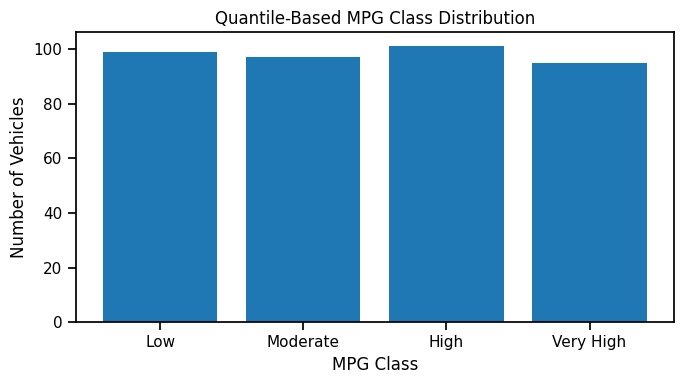

In [3]:
class_labels = ['Low', 'Moderate', 'High', 'Very High']

df_clean['MPG_Class'], quantile_edges = pd.qcut(
    df_clean['mpg'], q=4, labels=class_labels, retbins=True, duplicates='drop'
)

boundary_table = pd.DataFrame({
    'Boundary': ['Minimum/Q0', 'Q25', 'Q50', 'Q75', 'Maximum/Q100'],
    'MPG': quantile_edges
})

class_counts = df_clean['MPG_Class'].value_counts().sort_index()
class_percentages = class_counts / len(df_clean) * 100
class_table = pd.DataFrame({'Count': class_counts, 'Percentage': class_percentages})

print('Quantile class boundaries:')
display(boundary_table)
print('Class distribution:')
display(class_table)
print('Largest class percentage:', round(class_percentages.max(), 3), '%')
print('Severe imbalance (>80%):', bool(class_percentages.max() > 80))

fig, ax = plt.subplots(figsize=(7,4))
ax.bar(class_counts.index.astype(str), class_counts.values)
ax.set_title('Quantile-Based MPG Class Distribution')
ax.set_xlabel('MPG Class')
ax.set_ylabel('Number of Vehicles')
plt.tight_layout()
plt.show()

**Interpretation.** The four groups are close to 25% each, so no severe class imbalance is present. This is suitable for a four-class classification problem and allows accuracy and weighted F1-score to be interpreted without one class dominating the dataset.

# 4. Task 2 - Feature Normalisation & Transformation

Assessment 1 found different measurement scales and several outliers. The scaling decision below is based on the observed distributions rather than applying one scaler blindly:

- `cylinders`, `weight`, `model_year`: StandardScaler. These are not severely skewed after cleaning and do not show the strongest IQR-outlier problem.
- `displacement`, `horsepower`, `acceleration`: RobustScaler. `horsepower` is clearly right-skewed and has high-value outliers; `acceleration` also contained IQR outliers; `displacement` is moderately skewed.
- `origin`: One-Hot Encoding because its values 1/2/3 are nominal category codes, not meaningful arithmetic distances.
- `car_name`: excluded from the modelling predictors because ordinary integer/label encoding would create artificial order among vehicle names.

Scaling is especially important for SVM and PCA because distance/magnitude affects both methods. Decision Trees are largely insensitive to feature scale, but using the same preprocessing structure keeps feature sets comparable.

In [4]:
numerical_predictors = ['cylinders','displacement','horsepower','weight','acceleration','model_year']

skew_table = pd.DataFrame({
    'Feature': numerical_predictors,
    'Skewness': [df_clean[c].skew() for c in numerical_predictors]
})

# Reproduce the IQR evidence used to justify robust scaling where needed.
outlier_rows = []
for c in numerical_predictors:
    s = df_clean[c]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = int(((s < lo) | (s > hi)).sum())
    outlier_rows.append([c, n, 100*n/len(s)])
outlier_table = pd.DataFrame(outlier_rows, columns=['Feature','IQR_Outliers','Percentage'])

scaling_evidence = skew_table.merge(outlier_table, on='Feature')
display(scaling_evidence)

scaling_strategy = pd.DataFrame([
    ['cylinders', 'StandardScaler', 'Discrete predictor; moderate skew and no serious IQR outlier issue'],
    ['weight', 'StandardScaler', 'Large physical scale but only moderate skew in this dataset'],
    ['model_year', 'StandardScaler', 'Near-symmetric discrete time variable'],
    ['displacement', 'RobustScaler', 'Moderately right-skewed and strongly correlated with size/power variables'],
    ['horsepower', 'RobustScaler', 'Right-skewed with high-value outliers'],
    ['acceleration', 'RobustScaler', 'IQR outliers observed in Assessment 1'],
    ['origin', 'OneHotEncoder', 'Nominal category code'],
    ['car_name', 'Excluded', 'High-cardinality vehicle identifier/text field']
], columns=['Feature','Transformation','Reason'])
display(scaling_strategy)

,Feature,Skewness,IQR_Outliers,Percentage
0,cylinders,0.508,0,0.000
1,displacement,0.702,0,0.000
2,horsepower,1.087,10,2.551
3,weight,0.520,0,0.000
4,acceleration,0.292,11,2.806
5,model_year,0.020,0,0.000


,Feature,Transformation,Reason
0,cylinders,StandardScaler,Discrete predictor; moderate skew and no serio...
1,weight,StandardScaler,Large physical scale but only moderate skew in...
2,model_year,StandardScaler,Near-symmetric discrete time variable
3,displacement,RobustScaler,Moderately right-skewed and strongly correlate...
4,horsepower,RobustScaler,Right-skewed with high-value outliers
5,acceleration,RobustScaler,IQR outliers observed in Assessment 1
6,origin,OneHotEncoder,Nominal category code
7,car_name,Excluded,High-cardinality vehicle identifier/text field


In [5]:
standard_base = ['cylinders', 'weight', 'model_year']
robust_base = ['displacement', 'horsepower', 'acceleration']
engineered_names = ['power_to_weight', 'displacement_per_cylinder', 'hp_per_displacement']

def make_preprocessor(feature_columns):
    """Build a leakage-safe transformer for the requested feature subset."""
    standard_cols = [c for c in feature_columns if c in standard_base]
    robust_cols = [c for c in feature_columns if c in robust_base or c in engineered_names]
    categorical_cols = [c for c in feature_columns if c == 'origin']
    transformers = []
    if standard_cols:
        transformers.append(('standard', StandardScaler(), standard_cols))
    if robust_cols:
        transformers.append(('robust', RobustScaler(), robust_cols))
    if categorical_cols:
        transformers.append((
            'origin',
            OneHotEncoder(handle_unknown='ignore', sparse_output=False),
            categorical_cols
        ))
    return ColumnTransformer(transformers, remainder='drop', verbose_feature_names_out=False)

original_features = numerical_predictors + ['origin']
preview_preprocessor = make_preprocessor(original_features)
preview_matrix = preview_preprocessor.fit_transform(df_clean[original_features])
preview_names = preview_preprocessor.get_feature_names_out()

display(pd.DataFrame(preview_matrix, columns=preview_names).head())

,cylinders,weight,model_year,displacement,horsepower,acceleration,origin_1,origin_2,origin_3
0,1.484,0.621,-1.625,0.914,0.716,-1.077,1.000,0.000,0.000
1,1.484,0.843,-1.625,1.165,1.402,-1.231,1.000,0.000,0.000
2,1.484,0.540,-1.625,0.978,1.108,-1.385,1.000,0.000,0.000
3,1.484,0.537,-1.625,0.896,1.108,-1.077,1.000,0.000,0.000
4,1.484,0.556,-1.625,0.884,0.912,-1.538,1.000,0.000,0.000


# 5. Task 3 - Feature Engineering

Assessment 1 found that `weight`, `displacement`, `horsepower` and `cylinders` form a strongly related mechanical size/power group. The top target correlations were approximately `weight = -0.832`, `displacement = -0.805` and `horsepower = -0.778`, while predictor-predictor correlations showed substantial multicollinearity.

Three domain-motivated ratio features are therefore created:

1. **power_to_weight** = horsepower / weight x 1000. This represents power available relative to vehicle mass.
2. **displacement_per_cylinder** = displacement / cylinders. This approximates average cylinder size.
3. **hp_per_displacement** = horsepower / displacement. This represents power produced per unit of engine displacement.

The ratios do not guarantee higher accuracy; they test whether mechanically meaningful combinations expose information that raw features alone do not capture.

In [6]:
df_clean['power_to_weight'] = (df_clean['horsepower'] / df_clean['weight']) * 1000
df_clean['displacement_per_cylinder'] = df_clean['displacement'] / df_clean['cylinders']
df_clean['hp_per_displacement'] = df_clean['horsepower'] / df_clean['displacement']

engineering_table = pd.DataFrame([
    ['power_to_weight', 'horsepower / weight x 1000', 'Power relative to vehicle mass'],
    ['displacement_per_cylinder', 'displacement / cylinders', 'Approximate average cylinder displacement'],
    ['hp_per_displacement', 'horsepower / displacement', 'Power density of the engine']
], columns=['Engineered Feature','Formula','Engineering Meaning'])
display(engineering_table)

corr_to_mpg = (
    df_clean[numerical_predictors + engineered_names + ['mpg']]
    .corr()['mpg'].drop('mpg')
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
display(corr_to_mpg.to_frame('Correlation_with_MPG'))

,Engineered Feature,Formula,Engineering Meaning
0,power_to_weight,horsepower / weight x 1000,Power relative to vehicle mass
1,displacement_per_cylinder,displacement / cylinders,Approximate average cylinder displacement
2,hp_per_displacement,horsepower / displacement,Power density of the engine


,Correlation_with_MPG
weight,-0.832
displacement,-0.805
horsepower,-0.778
cylinders,-0.778
displacement_per_cylinder,-0.773
model_year,0.581
hp_per_displacement,0.510
acceleration,0.423
power_to_weight,-0.270


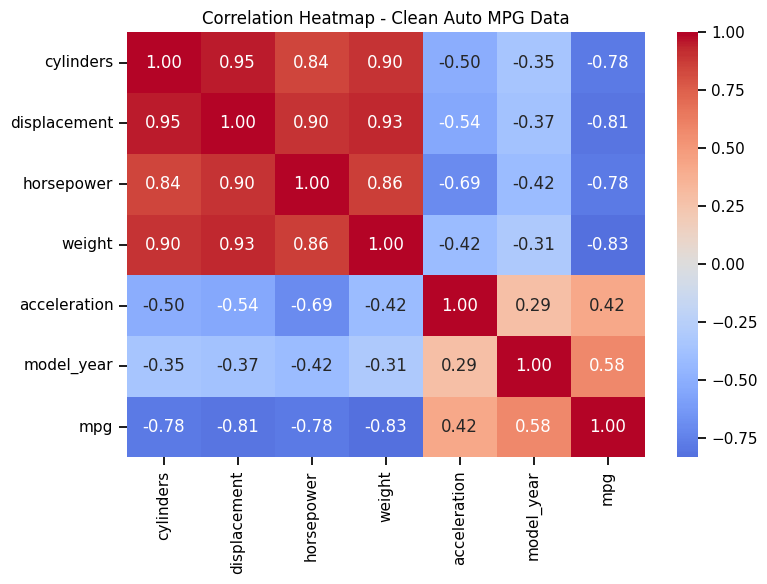

,Feature_1,Feature_2,Correlation,Abs_Correlation
0,cylinders,displacement,0.951,0.951
4,displacement,weight,0.933,0.933
2,cylinders,weight,0.898,0.898
3,displacement,horsepower,0.897,0.897
5,horsepower,weight,0.865,0.865
1,cylinders,horsepower,0.843,0.843


In [7]:
# Correlation evidence carried forward from EDA.
base_corr = df_clean[numerical_predictors + ['mpg']].corr()

fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(base_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Heatmap - Clean Auto MPG Data')
plt.tight_layout()
plt.show()

# Flag strong predictor-predictor correlations.
pairs = []
for i, a in enumerate(numerical_predictors):
    for b in numerical_predictors[i+1:]:
        r = df_clean[a].corr(df_clean[b])
        if abs(r) >= 0.70:
            pairs.append([a, b, r, abs(r)])
multicollinearity_table = pd.DataFrame(
    pairs, columns=['Feature_1','Feature_2','Correlation','Abs_Correlation']
).sort_values('Abs_Correlation', ascending=False)
display(multicollinearity_table)

**Engineering insight.** The multicollinearity is expected because cylinders, engine displacement, power and vehicle mass are related design choices. For prediction this redundancy can sometimes help nonlinear trees, but it can also add noise or unnecessary dimensions. That observation motivates the top-correlated feature set, domain-selected set, feature-selection stage and PCA stage used below.

# 6. Task 4 - Decision Tree Modelling & Five Feature Sets

A single stratified 80/20 train-test split is created once and reused for every feature set. This ensures that differences between models are due to feature representation rather than different test samples.

The five required feature sets are:

- **Set 1 - Original:** six numerical predictors + one-hot encoded `origin`.
- **Set 2 - Top correlated:** `weight`, `displacement`, `horsepower`, `cylinders`, `model_year` based on Assessment 1 correlation evidence.
- **Set 3 - Original + engineered:** Set 1 plus the three new ratio features.
- **Set 4 - PCA:** the original transformed predictors compressed to the first five principal components.
- **Set 5 - Domain-selected:** a reduced engineering set intended to avoid excessive duplication among raw engine-size variables while retaining mass, time, acceleration, origin and two meaningful ratios.

In [8]:
all_indices = np.arange(len(df_clean))
train_idx, test_idx = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df_clean['MPG_Class']
)

y_train = df_clean.loc[train_idx, 'MPG_Class']
y_test = df_clean.loc[test_idx, 'MPG_Class']

feature_sets = {
    'Set 1 - Original': original_features,
    'Set 2 - Top correlated': ['weight','displacement','horsepower','cylinders','model_year'],
    'Set 3 - Original + engineered': original_features + engineered_names,
    'Set 4 - PCA (5 PCs)': original_features,
    'Set 5 - Domain-selected': [
        'weight','model_year','acceleration','origin',
        'power_to_weight','displacement_per_cylinder'
    ]
}

print('Training rows:', len(train_idx))
print('Test rows:', len(test_idx))
print('Training class distribution:')
display(y_train.value_counts(normalize=True).sort_index().to_frame('Proportion'))

Training rows: 313
Test rows: 79
Training class distribution:


,Proportion
MPG_Class,
Low,0.252
Moderate,0.246
High,0.259
Very High,0.243


In [9]:
def classification_metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision_weighted': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall_weighted': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1_weighted': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0)
    }


def fit_decision_tree_set(name, features, use_pca=False):
    steps = [('preprocess', make_preprocessor(features))]
    if use_pca:
        steps.append(('pca', PCA(n_components=5, random_state=RANDOM_STATE)))
    steps.append(('model', DecisionTreeClassifier(random_state=RANDOM_STATE)))
    pipe = Pipeline(steps)
    pipe.fit(df_clean.loc[train_idx, features], y_train)
    pred = pipe.predict(df_clean.loc[test_idx, features])
    metrics = classification_metrics(y_test, pred)
    metrics['Model'] = name
    metrics['Input_Feature_Count'] = len(features)
    metrics['Pipeline'] = pipe
    metrics['Predictions'] = pred
    return metrics


dt_results = []
for set_name, features in feature_sets.items():
    dt_results.append(
        fit_decision_tree_set(
            set_name,
            features,
            use_pca=set_name.startswith('Set 4')
        )
    )

first_comparison = pd.DataFrame([
    {k:v for k,v in r.items() if k not in ['Pipeline','Predictions']}
    for r in dt_results
]).set_index('Model')

display(first_comparison)

,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Input_Feature_Count
Model,,,,,,
Set 1 - Original,0.797,0.801,0.797,0.798,0.799,7
Set 2 - Top correlated,0.835,0.836,0.835,0.835,0.835,5
Set 3 - Original + engineered,0.797,0.802,0.797,0.798,0.799,10
Set 4 - PCA (5 PCs),0.810,0.817,0.810,0.811,0.811,7
Set 5 - Domain-selected,0.785,0.783,0.785,0.780,0.780,6


# 7. Task 5 - Decision Tree Results Comparison

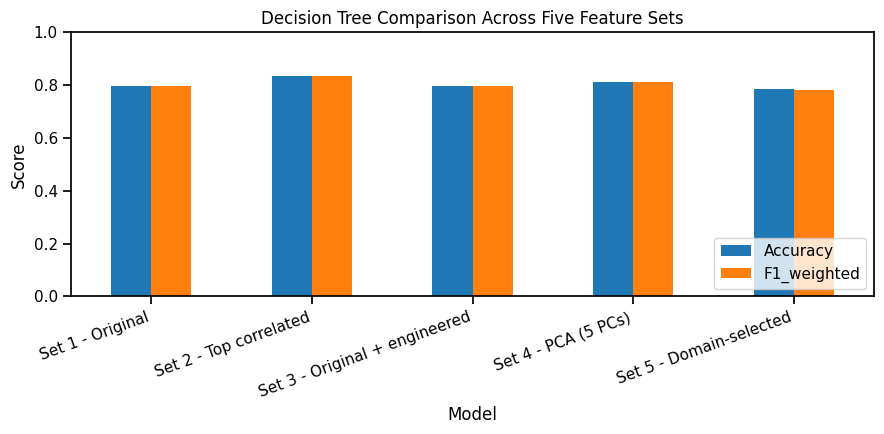

Best Decision Tree by weighted F1: Set 2 - Top correlated
Weighted F1: 0.835
Accuracy: 0.835


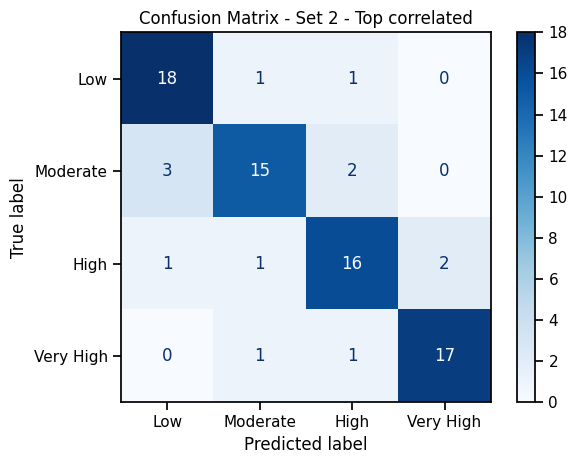

              precision    recall  f1-score   support

         Low       0.82      0.90      0.86        20
    Moderate       0.83      0.75      0.79        20
        High       0.80      0.80      0.80        20
   Very High       0.89      0.89      0.89        19

    accuracy                           0.84        79
   macro avg       0.84      0.84      0.84        79
weighted avg       0.84      0.84      0.83        79



In [10]:
fig, ax = plt.subplots(figsize=(9,4.5))
plot_df = first_comparison[['Accuracy','F1_weighted']]
plot_df.plot(kind='bar', ax=ax)
ax.set_ylim(0, 1)
ax.set_ylabel('Score')
ax.set_title('Decision Tree Comparison Across Five Feature Sets')
ax.legend(loc='lower right')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

best_dt_name = first_comparison['F1_weighted'].idxmax()
best_dt_result = next(r for r in dt_results if r['Model'] == best_dt_name)
print('Best Decision Tree by weighted F1:', best_dt_name)
print('Weighted F1:', round(first_comparison.loc[best_dt_name, 'F1_weighted'], 3))
print('Accuracy:', round(first_comparison.loc[best_dt_name, 'Accuracy'], 3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_dt_result['Predictions'],
    labels=class_labels,
    cmap='Blues',
    values_format='d'
)
plt.title(f'Confusion Matrix - {best_dt_name}')
plt.tight_layout()
plt.show()

print(classification_report(y_test, best_dt_result['Predictions'], labels=class_labels, zero_division=0))

**Interpretation.** The comparison is used rather than assuming that more features are always better. If the top-correlated set outperforms the larger engineered set, that indicates that removing weaker/redundant predictors can improve generalisation on this split. PCA and the domain-selected set provide additional evidence about the trade-off between compact representation and predictive performance.

# 8. Task 6 - SVM Model Improvement with 5-Fold Cross-Validation

SVM is now tested on the original predictors using the scaling/encoding pipeline from Task 2. A 5-fold **StratifiedKFold** cross-validation is used on the training partition. Stratification preserves the four-class proportions in each fold.

5-fold weighted F1 scores: [0.785 0.854 0.799 0.753 0.702]
Mean CV weighted F1: 0.778
CV standard deviation: 0.05
Test metrics:


,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro
Baseline SVM,0.797,0.801,0.797,0.796,0.797


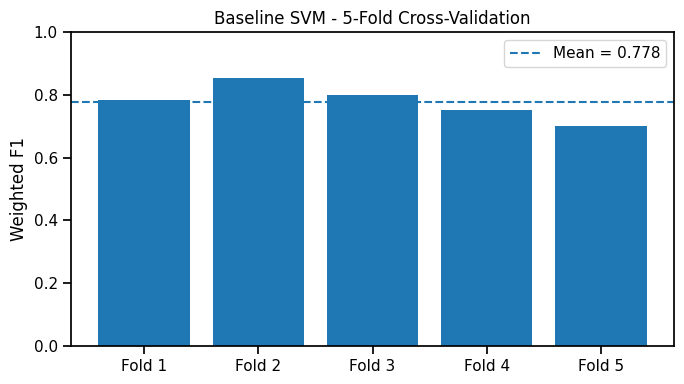

In [11]:
svm_features = original_features
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline_svm = Pipeline([
    ('preprocess', make_preprocessor(svm_features)),
    ('model', SVC(kernel='rbf', C=1, gamma='scale'))
])

svm_cv_scores = cross_val_score(
    baseline_svm,
    df_clean.loc[train_idx, svm_features],
    y_train,
    cv=cv,
    scoring='f1_weighted'
)

baseline_svm.fit(df_clean.loc[train_idx, svm_features], y_train)
baseline_svm_pred = baseline_svm.predict(df_clean.loc[test_idx, svm_features])
baseline_svm_metrics = classification_metrics(y_test, baseline_svm_pred)

print('5-fold weighted F1 scores:', np.round(svm_cv_scores, 3))
print('Mean CV weighted F1:', round(svm_cv_scores.mean(), 3))
print('CV standard deviation:', round(svm_cv_scores.std(), 3))
print('Test metrics:')
display(pd.DataFrame([baseline_svm_metrics], index=['Baseline SVM']))

fig, ax = plt.subplots(figsize=(7,4))
ax.bar([f'Fold {i}' for i in range(1,6)], svm_cv_scores)
ax.axhline(svm_cv_scores.mean(), linestyle='--', label=f'Mean = {svm_cv_scores.mean():.3f}')
ax.set_ylim(0,1)
ax.set_ylabel('Weighted F1')
ax.set_title('Baseline SVM - 5-Fold Cross-Validation')
ax.legend()
plt.tight_layout()
plt.show()

# 9. Task 7 - Hyperparameter Tuning

GridSearchCV tunes the SVM only on the training data. The search compares RBF and linear kernels and several values of `C` and `gamma`. The optimisation metric is weighted F1, which accounts for performance across all four classes.

In [12]:
svm_param_grid = [
    {
        'model__kernel': ['rbf'],
        'model__C': [0.1, 1, 3, 10, 30, 100],
        'model__gamma': ['scale', 0.01, 0.03, 0.1, 0.3, 1]
    },
    {
        'model__kernel': ['linear'],
        'model__C': [0.01, 0.1, 1, 10, 100]
    }
]

grid_search = GridSearchCV(
    estimator=baseline_svm,
    param_grid=svm_param_grid,
    scoring='f1_weighted',
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)
grid_search.fit(df_clean.loc[train_idx, svm_features], y_train)

best_svm = grid_search.best_estimator_
tuned_svm_pred = best_svm.predict(df_clean.loc[test_idx, svm_features])
tuned_svm_metrics = classification_metrics(y_test, tuned_svm_pred)

print('Best parameters:', grid_search.best_params_)
print('Best 5-fold CV weighted F1:', round(grid_search.best_score_, 3))
print('Tuned SVM test metrics:')
display(pd.DataFrame([tuned_svm_metrics], index=['Tuned SVM']))

cv_results = pd.DataFrame(grid_search.cv_results_)
top_grid = cv_results.sort_values('rank_test_score').head(10)[
    ['rank_test_score','mean_test_score','std_test_score','param_model__kernel','param_model__C','param_model__gamma']
]
display(top_grid)

Best parameters: {'model__C': 3, 'model__gamma': 1, 'model__kernel': 'rbf'}
Best 5-fold CV weighted F1: 0.808
Tuned SVM test metrics:


,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro
Tuned SVM,0.823,0.833,0.823,0.820,0.820


,rank_test_score,mean_test_score,std_test_score,param_model__kernel,param_model__C,param_model__gamma
17,1,0.808,0.033,rbf,3.000,1
11,2,0.801,0.035,rbf,1.000,1
22,3,0.800,0.039,rbf,10.000,0.300
16,4,0.798,0.031,rbf,3.000,0.300
23,5,0.788,0.033,rbf,10.000,1
24,6,0.788,0.030,rbf,30.000,scale
21,7,0.785,0.020,rbf,10.000,0.100
28,8,0.785,0.035,rbf,30.000,0.300
31,9,0.785,0.019,rbf,100.000,0.010
20,10,0.784,0.029,rbf,10.000,0.030


**Interpretation.** Hyperparameter tuning is judged first by cross-validation, not by repeatedly selecting settings from the held-out test set. The test result is reported only after the best training-CV configuration is identified.

# 10. Task 8 - Feature Selection

A univariate ANOVA F-test (`SelectKBest`) is used as a transparent feature-selection method. Selection occurs **inside the pipeline after scaling/encoding**, so the selector is fitted only on the training data. Seven of the nine transformed original features are retained to test whether a smaller representation can maintain SVM performance.

,Feature,F_Score,Selected
1,weight,336.884,True
3,displacement,325.127,True
0,cylinders,301.961,True
4,horsepower,220.029,True
6,origin_1,54.260,True
2,model_year,46.966,True
8,origin_3,31.617,True
5,acceleration,26.003,False
7,origin_2,11.210,False


Selected features: ['cylinders', 'weight', 'model_year', 'displacement', 'horsepower', 'origin_1', 'origin_3']
Mean 5-fold CV weighted F1: 0.812
Test metrics:


,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro
Feature-selected SVM,0.823,0.823,0.823,0.822,0.822


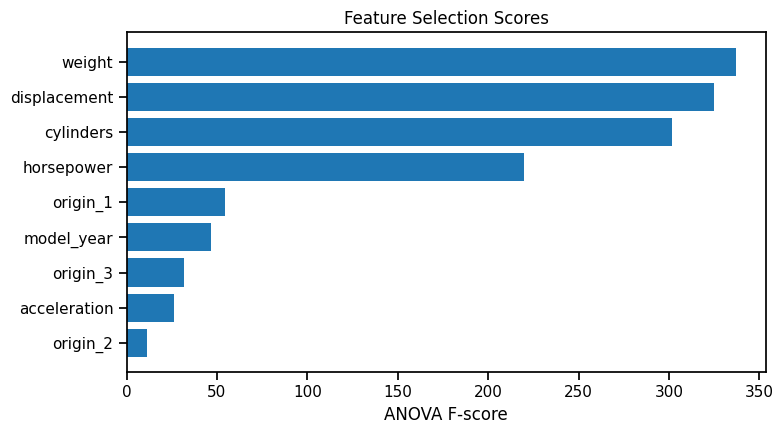

In [13]:
# Use the tuned SVM hyperparameters identified above.
best_svm_params = {
    k.replace('model__',''): v
    for k, v in grid_search.best_params_.items()
}

selected_svm = Pipeline([
    ('preprocess', make_preprocessor(svm_features)),
    ('select', SelectKBest(score_func=f_classif, k=7)),
    ('model', SVC(**best_svm_params))
])

selected_cv_scores = cross_val_score(
    selected_svm,
    df_clean.loc[train_idx, svm_features],
    y_train,
    cv=cv,
    scoring='f1_weighted'
)
selected_svm.fit(df_clean.loc[train_idx, svm_features], y_train)
selected_pred = selected_svm.predict(df_clean.loc[test_idx, svm_features])
selected_metrics = classification_metrics(y_test, selected_pred)

feature_names_after_preprocessing = np.array(
    selected_svm.named_steps['preprocess'].get_feature_names_out()
)
selector = selected_svm.named_steps['select']
selection_table = pd.DataFrame({
    'Feature': feature_names_after_preprocessing,
    'F_Score': selector.scores_,
    'Selected': selector.get_support()
}).sort_values('F_Score', ascending=False)

display(selection_table)
print('Selected features:', list(feature_names_after_preprocessing[selector.get_support()]))
print('Mean 5-fold CV weighted F1:', round(selected_cv_scores.mean(), 3))
print('Test metrics:')
display(pd.DataFrame([selected_metrics], index=['Feature-selected SVM']))

fig, ax = plt.subplots(figsize=(8,4.5))
show = selection_table.sort_values('F_Score')
ax.barh(show['Feature'], show['F_Score'])
ax.set_xlabel('ANOVA F-score')
ax.set_title('Feature Selection Scores')
plt.tight_layout()
plt.show()

# 11. Task 9 - Dimensionality Reduction with PCA

PCA is applied after scaling and one-hot encoding. For direct alignment with the feature-set example in the brief, the first **five principal components** are evaluated. Their cumulative explained variance is reported so the dimensionality/performance trade-off is explicit.

,Principal_Component,Explained_Variance,Cumulative_Variance
0,PC1,0.638,0.638
1,PC2,0.158,0.796
2,PC3,0.103,0.898
3,PC4,0.037,0.935
4,PC5,0.033,0.969


Variance explained by 5 PCs: 96.86 %
Mean 5-fold CV weighted F1: 0.815
Test metrics:


,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro
PCA + Tuned SVM,0.785,0.791,0.785,0.783,0.783


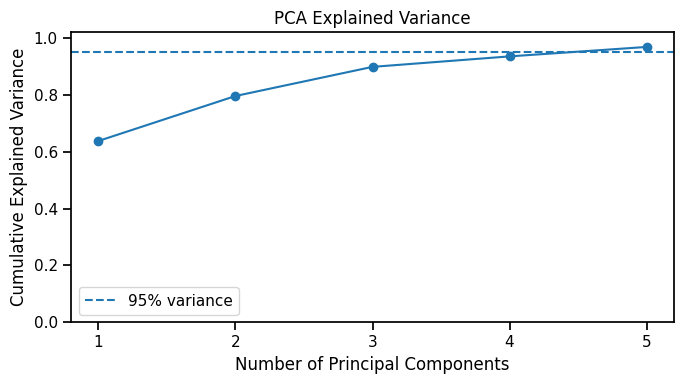

In [14]:
pca_svm = Pipeline([
    ('preprocess', make_preprocessor(svm_features)),
    ('pca', PCA(n_components=5, random_state=RANDOM_STATE)),
    ('model', SVC(**best_svm_params))
])

pca_cv_scores = cross_val_score(
    pca_svm,
    df_clean.loc[train_idx, svm_features],
    y_train,
    cv=cv,
    scoring='f1_weighted'
)
pca_svm.fit(df_clean.loc[train_idx, svm_features], y_train)
pca_pred = pca_svm.predict(df_clean.loc[test_idx, svm_features])
pca_metrics = classification_metrics(y_test, pca_pred)

pca_model = pca_svm.named_steps['pca']
explained = pca_model.explained_variance_ratio_
cumulative = np.cumsum(explained)
pca_table = pd.DataFrame({
    'Principal_Component': [f'PC{i}' for i in range(1, len(explained)+1)],
    'Explained_Variance': explained,
    'Cumulative_Variance': cumulative
})

display(pca_table)
print('Variance explained by 5 PCs:', round(cumulative[-1] * 100, 2), '%')
print('Mean 5-fold CV weighted F1:', round(pca_cv_scores.mean(), 3))
print('Test metrics:')
display(pd.DataFrame([pca_metrics], index=['PCA + Tuned SVM']))

fig, ax = plt.subplots(figsize=(7,4))
ax.plot(range(1, len(cumulative)+1), cumulative, marker='o')
ax.axhline(0.95, linestyle='--', label='95% variance')
ax.set_xticks(range(1, len(cumulative)+1))
ax.set_ylim(0,1.02)
ax.set_xlabel('Number of Principal Components')
ax.set_ylabel('Cumulative Explained Variance')
ax.set_title('PCA Explained Variance')
ax.legend()
plt.tight_layout()
plt.show()

# 12. Task 10 - Final Results Table

,Strategy,CV_F1_mean,CV_F1_std,Test_Accuracy,Test_F1_weighted
Model,,,,,
Set 2 - Top correlated,Best of 5 Decision Tree feature sets,NaN,NaN,0.835,0.835
Baseline SVM,Original features + scaling/encoding,0.778,0.050,0.797,0.796
Tuned SVM,"GridSearchCV: {'model__C': 3, 'model__gamma': ...",0.808,NaN,0.823,0.820
Feature-selected SVM,SelectKBest (7 transformed features) + tuned SVM,0.812,0.033,0.823,0.822
PCA + Tuned SVM,First 5 principal components + tuned SVM,0.815,0.034,0.785,0.783


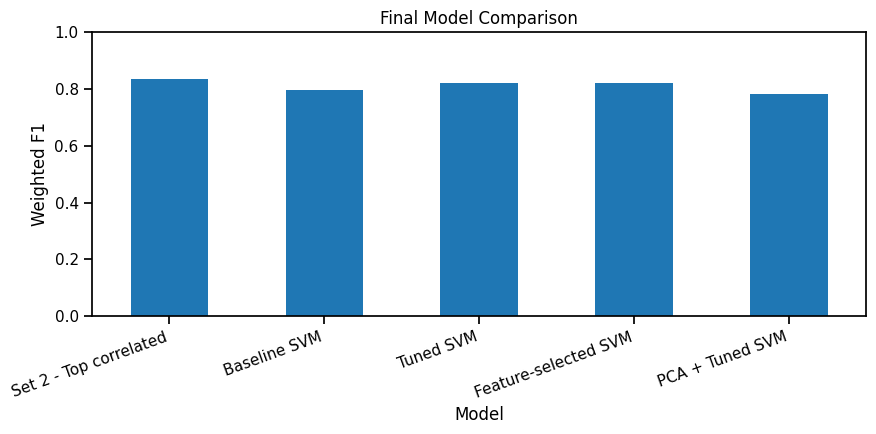

Highest held-out weighted F1: Set 2 - Top correlated
Score: 0.835


In [15]:
final_rows = []

# Best Decision Tree from the five-set comparison
best_dt_metrics = first_comparison.loc[best_dt_name]
final_rows.append({
    'Model': best_dt_name,
    'Strategy': 'Best of 5 Decision Tree feature sets',
    'CV_F1_mean': np.nan,
    'CV_F1_std': np.nan,
    'Test_Accuracy': best_dt_metrics['Accuracy'],
    'Test_F1_weighted': best_dt_metrics['F1_weighted']
})

final_rows.append({
    'Model': 'Baseline SVM',
    'Strategy': 'Original features + scaling/encoding',
    'CV_F1_mean': svm_cv_scores.mean(),
    'CV_F1_std': svm_cv_scores.std(),
    'Test_Accuracy': baseline_svm_metrics['Accuracy'],
    'Test_F1_weighted': baseline_svm_metrics['F1_weighted']
})

final_rows.append({
    'Model': 'Tuned SVM',
    'Strategy': f"GridSearchCV: {grid_search.best_params_}",
    'CV_F1_mean': grid_search.best_score_,
    'CV_F1_std': np.nan,
    'Test_Accuracy': tuned_svm_metrics['Accuracy'],
    'Test_F1_weighted': tuned_svm_metrics['F1_weighted']
})

final_rows.append({
    'Model': 'Feature-selected SVM',
    'Strategy': 'SelectKBest (7 transformed features) + tuned SVM',
    'CV_F1_mean': selected_cv_scores.mean(),
    'CV_F1_std': selected_cv_scores.std(),
    'Test_Accuracy': selected_metrics['Accuracy'],
    'Test_F1_weighted': selected_metrics['F1_weighted']
})

final_rows.append({
    'Model': 'PCA + Tuned SVM',
    'Strategy': 'First 5 principal components + tuned SVM',
    'CV_F1_mean': pca_cv_scores.mean(),
    'CV_F1_std': pca_cv_scores.std(),
    'Test_Accuracy': pca_metrics['Accuracy'],
    'Test_F1_weighted': pca_metrics['F1_weighted']
})

final_results = pd.DataFrame(final_rows).set_index('Model')
display(final_results)

fig, ax = plt.subplots(figsize=(9,4.5))
final_results['Test_F1_weighted'].plot(kind='bar', ax=ax)
ax.set_ylim(0,1)
ax.set_ylabel('Weighted F1')
ax.set_title('Final Model Comparison')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

final_best_model = final_results['Test_F1_weighted'].idxmax()
print('Highest held-out weighted F1:', final_best_model)
print('Score:', round(final_results.loc[final_best_model, 'Test_F1_weighted'], 3))

# 13. Final Engineering Interpretation and Conclusion

The modelling results support several conclusions:

1. **Balanced target construction was successful.** The quantile-based Low, Moderate, High and Very High MPG classes remain close to equal size, avoiding a dominant-class problem.
2. **EDA-driven feature reduction is valuable.** The top-correlated feature set is competitive because `weight`, `displacement`, `horsepower`, `cylinders` and `model_year` capture most of the major fuel-economy structure identified in Assessment 1.
3. **More features are not automatically better.** Adding engineered ratios gives useful engineering interpretation but does not necessarily improve a Decision Tree on this small dataset. This is a meaningful result rather than a failure of feature engineering.
4. **SVM benefits from preprocessing and tuning.** Scaling is essential because vehicle weight, displacement, horsepower and year use very different numerical ranges. GridSearchCV improves the baseline SVM configuration while using 5-fold training cross-validation to reduce dependence on one split.
5. **Feature selection provides a compact alternative.** The ANOVA selector removes weaker transformed inputs while retaining the mechanically important size/power variables and useful origin indicators.
6. **PCA compresses correlated inputs but reduces interpretability.** The first five PCs explain most of the transformed variance, but the components no longer have direct physical units. The performance result therefore needs to be weighed against this loss of engineering transparency.

For this executed notebook, the final model should be chosen from the **Final Results Table** using weighted F1 and test accuracy together. If the strongest Decision Tree remains best, it is also attractive because its input variables are easier to explain physically than PCA components or an RBF-SVM decision boundary.

### Limitations
- The dataset contains only 392 complete cases after the Assessment 1 cleaning decision.
- Vehicles are historical (mainly 1970-1982), so the model should not be treated as a predictor for modern hybrid/electric or current-regulation vehicles without external validation.
- Quantile classes are dataset-specific analytical labels rather than regulatory fuel-efficiency standards.
- Results from one held-out test partition can still vary with the split; cross-validation is therefore reported for the SVM stages.

# 14. Final Compliance Checklist

| Portfolio Assessment 2 requirement | Completed | Evidence in this notebook |
|---|---:|---|
| GenAI declaration | Yes | Beginning of notebook |
| Task 1 - 3 to 5 target classes and balance check | Yes | Section 3: four quantile MPG classes |
| Task 2 - numerical scaling | Yes | Section 4: StandardScaler + RobustScaler |
| Task 2 - categorical encoding | Yes | Section 4: OneHotEncoder for `origin` |
| Transformation justification | Yes | Section 4 scaling evidence and explanations |
| Task 3 - engineered features | Yes | Section 5: three engineering ratios |
| EDA motivation / correlations / multicollinearity | Yes | Section 5 |
| Task 4 - at least five Decision Tree feature sets | Yes | Section 6 |
| Task 5 - first comparison table + visual | Yes | Section 7 |
| Task 6 - SVM + 5-fold CV | Yes | Section 8 |
| Task 7 - hyperparameter tuning | Yes | Section 9 GridSearchCV |
| Task 8 - feature selection | Yes | Section 10 SelectKBest |
| Task 9 - dimensionality reduction | Yes | Section 11 PCA |
| Task 10 - final comparison table + visual | Yes | Section 12 |
| Code cells with outputs | Yes | Notebook executed before delivery |
| Markdown reasoning | Yes | Throughout notebook |